## EDA: Entendimiento

- Se describe el dataset y el negocio

- Se lee la data a `data/bronze/` y se aplana a `data/staging/`

### Utilidades

In [1]:
NOTEBOOK = "a_entendimiento"
%run ../funciones.ipynb
%run funciones.ipynb

In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 8
Memoria driver: 3.0 GB
UI del job    : http://localhost:4040


---

### **1. Negocio**

#### a. Fuente y proceso

- Portal de Contrataciones Abiertas del OECE, que publica los procesos del SEACE

- **Proceso**: entidad pública (ministerio, municipalidad, hospital) necesita comprar un bien, servicio u obra

#### b. Etapas

  - `planning`: requerimiento y presupuesto

  - `tender`: convocatoria, ítems, monto referencial y postores (`tenderers`)

  - `awards`: adjudicación, es decir, quién gana, por cuánto y en qué ítems

  - `contracts`: contrato firmado con el ganador

#### c. Actores

  - `buyer` / `procuringEntity`: la entidad

  - `tenderer`: proveedor que participa

  - `supplier`: proveedor que gana

#### d. Método

- Licitación, concurso, adjudicación simplificada, subasta, comparación de precios, contratación directa

- La contratación directa no tiene competencia

### **2. Problema**

#### a. PQ1 - Concentración y cautividad 

¿Qué entidades dependen de pocos proveedores y qué proveedores concentran el gasto de muchas entidades?

#### b. PQ2 - Mercados y competencia 

¿Qué mercados emergen de la co-participación? ¿Son regionales o por rubro? ¿Qué grupos de proveedores compiten siempre entre sí?

#### c. PQ3 - Sustitutos y afinidades inusuales 

Para una entidad, ¿qué proveedores son alternativas según entidades parecidas, y qué relaciones entidad–proveedor son atípicas?


---

### **3. Datos originales**

<pre style="background: none; border: none; padding: 0;">
data/raw/&lt;año&gt;/&lt;mes&gt;.json
├── uri, version, publisher, license, publishedDate
└── records[]
    ├── ocid
    ├── releases[]
    └── compiledRelease
        ├── ocid
        ├── date
        ├── dataSegmentation {id, criteria[]}
        │
        ├── buyer {id, name}
        │
        ├── tender
        │   ├── id, title, description
        │   ├── procurementMethodDetails
        │   ├── mainProcurementCategory
        │   ├── value {amount, currency, amount_PEN}
        │   ├── numberOfTenderers
        │   ├── tenderPeriod {startDate, endDate}
        │   ├── procuringEntity {id, name}
        │   ├── items[]
        │   │   ├── id, description, quantity
        │   │   ├── classification {scheme, id}
        │   │   ├── additionalClassifications[]
        │   │   └── unit, totalValue, status
        │   └── tenderers[] {id, name}
        │
        ├── awards[]
        │   ├── id, date
        │   ├── value {amount, currency}
        │   ├── suppliers[] {id, name}
        │   └── items[] {classification ...}
        │
        ├── contracts[]
        │   ├── id, awardID
        │   ├── value {amount, currency}
        │   ├── dateSigned
        │   └── period, implementation, items[]
        │
        └── parties[]
            ├── id, name
            ├── identifier {scheme, id, legalName}
            ├── additionalIdentifiers[] {scheme, id}
            ├── roles[]
            └── address {region, department, ...}
</pre>

### **4. Lectura de datos**

#### a. Capa bronze

In [3]:
archivos = listar_archivos(raw_dir, anios)
mb_json = sum(a.stat().st_size for a in archivos) / 1024**2
rel = extraer_releases(leer_json(spark, archivos))

campos = [c for c in ["ocid", "date", "buyer", "tender", "awards", "contracts", "parties"] if c in rel.columns]
(rel.select(*[sin_documentos(c) for c in campos], F.input_file_name().alias("_archivo"))
    .write.mode("overwrite").parquet(str(bronze_dir)))

bronze = spark.read.parquet(str(bronze_dir))
existe, col, sub, explotar = crear_vista(bronze)
mb_bronze = sum(f.stat().st_size for f in bronze_dir.rglob("*.parquet")) / 1024**2
print(f"{len(archivos)} archivos | JSON {mb_json:,.0f} MB -> bronze {mb_bronze:,.0f} MB")

36 archivos | JSON 3,867 MB -> bronze 264 MB


- Bronze guarda la estructura anidada en Parquet

- Cada tabla siguiente lee solo las columnas que usa

- `documents` se descarta: millones de objetos no usados

#### b. Aplanado a staging

In [4]:
tablas_staging = {
    "procesos": t_procesos(bronze, existe, col),
    "adjudicaciones": t_adjudicaciones(explotar, sub, existe),
    "oferentes": t_oferentes(explotar, sub),
    "items": t_items(explotar, sub, existe),
    "contratos": t_contratos(explotar, sub),
    "partes": t_partes(explotar, sub)}

tablas_staging["procesos"].write.mode("overwrite").partitionBy("anio").parquet(str(staging_dir / "procesos"))
anio_ocid = F.broadcast(leer(staging_dir, "procesos").select("ocid", "anio"))
for nombre, df in tablas_staging.items():
    if nombre != "procesos":
        df.join(anio_ocid, "ocid", "left").write.mode("overwrite").partitionBy("anio").parquet(str(staging_dir / nombre))

st = {n: leer(staging_dir, n) for n in tablas_staging}

- Todas las tablas se particionan por `anio`

#### c. Volumen

In [5]:
conteos = pd.DataFrame([(n, df.count(), df.select("ocid").distinct().count()) for n, df in st.items()],
                       columns=["tabla", "filas", "ocid_distintos"])
conteos["filas_por_ocid"] = (conteos.filas / conteos.ocid_distintos.clip(lower=1)).round(2)
conteos["mb_parquet"] = [round(sum(f.stat().st_size for f in (staging_dir / n).rglob("*.parquet")) / 1024**2, 1)
                         for n in conteos.tabla]
conteos

,tabla,filas,ocid_distintos,filas_por_ocid,mb_parquet
0,procesos,236261,236261,1.00,47.0
1,adjudicaciones,203533,185010,1.10,11.0
2,oferentes,2908120,215093,13.52,37.8
3,items,280452,236233,1.19,23.5
4,contratos,197000,171862,1.15,6.2
5,partes,3144386,236261,13.31,56.7


- **236,229 procesos** (sin repetidos) en 36 meses

- 184,969 procesos (78%) con al menos una adjudicación; resto quedó desierto, cancelado o sin publicar

- **13.5 oferentes por proceso** en promedio: `oferentes` (2.9M filas) es la tabla más grande y base de
  co-participación

- `adjudicaciones` tiene 1.10 filas por proceso con adjudicación: algunos procesos se adjudican por ítems o lotes

### **5. Datos aplanados**

<pre style="background: none; border: none; padding: 0;">
data/staging/
├── procesos
│   ├── ocid
│   ├── fecha, anio, anio_archivo, mes_archivo
│   ├── entidad_id_raw, entidad_ruc, entidad, region
│   ├── descripcion, items_desc
│   ├── metodo_detalle, categoria
│   ├── monto_referencial, moneda
│   └── n_postores
│
├── adjudicaciones
│   ├── ocid, anio
│   ├── award_id, fecha_adj, estado_adj
│   ├── monto_adj, moneda_adj
│   ├── proveedor_id_raw, proveedor, n_proveedores_adj
│   └── unspsc_adj
│
├── oferentes
│   ├── ocid, anio
│   └── oferente_id_raw, oferente
│
├── items
│   ├── ocid, anio
│   ├── item_id, item_desc, cantidad
│   └── unspsc
│
├── contratos
│   ├── ocid, anio
│   ├── contrato_id, award_id, estado_contrato
│   ├── monto_contrato, moneda_contrato
│   └── fecha_firma
│
└── partes
    ├── ocid, anio
    ├── parte_id_raw, nombre
    ├── identificador, esquema, roles
    └── region
</pre>

### **6. Columnas**

| Tabla | Columna | Información | Uso |
|---|---|---|---|
| **procesos** | `ocid` | Identificador único del proceso | Llave de todas las tablas |
| | `fecha` | Inicio de convocatoria (fecha de adjudicación o del release) | Partición `anio/mes` |
| | `entidad_id_raw`, `entidad_ruc`, `entidad` | Código CONSUCODE, RUC y nombre de la entidad | Nodo entidad |
| | `region` | Región de la entidad | Atributo de nodo, mercados regionales |
| | `descripcion`, `items_desc` | Objeto de la compra (texto) | Recomendación por contenido |
| | `metodo_detalle`, `categoria` | Método de selección; bienes/servicios/obras | Features de competencia y tipo |
| | `monto_referencial`, `moneda` | Valor estimado de la convocatoria | Features de monto |
| | `n_postores` | `numberOfTenderers` declarado | Postor único |
| **adjudicaciones** (award × proveedor) | `award_id`, `fecha_adj` | Adjudicación al ganador y su fecha | Arista entidad–proveedor |
| | `estado_adj` | Estado del award | Filtrar cancelados |
| | `monto_adj`, `moneda_adj` | Monto adjudicado | Peso de la arista |
| | `proveedor_id_raw`, `proveedor` | Ganador (RUC/código y nombre) | Nodo proveedor |
| | `unspsc_adj`, `n_proveedores_adj` | Rubros adjudicados; ganadores del award | Familia de la arista |
| **oferentes** (postor x proceso) | `oferente_id_raw`, `oferente` | Proveedores que participaron | Grafo de co-participación y tasa de éxito |
| **items** (ítem del tender) | `item_id`, `item_desc`, `cantidad`, `unspsc` | Ítem convocado y su código UNSPSC | Rubro (familia de 4 dígitos) |
| **contratos** (contrato) | `contrato_id`, `award_id`, `monto_contrato`, `fecha_firma` | Contrato y award al que pertenece | Atributo `tiene_contrato` |
| **partes** (parte × proceso) | `parte_id_raw`, `identificador`, `esquema`, `roles`, `region` | Catálogo de actores con su rol | Resolución de entidades, región del proveedor |

---

### **5. Calidad de datos**

#### a. Nulos en llaves

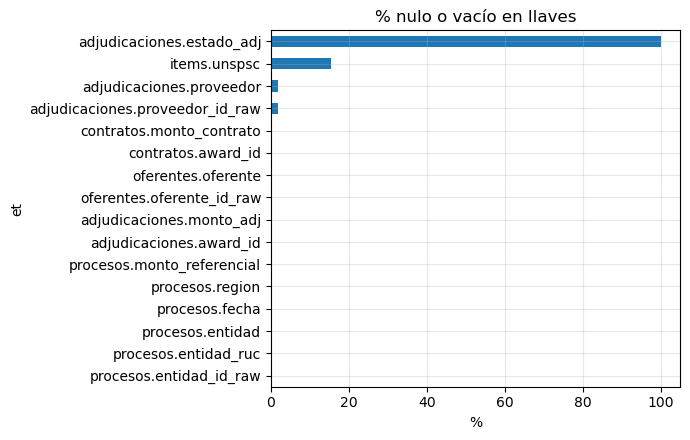

In [6]:
llaves = {"procesos": ["entidad_id_raw", "entidad_ruc", "entidad", "fecha", "region", "monto_referencial"],
          "adjudicaciones": ["award_id", "proveedor_id_raw", "proveedor", "monto_adj", "estado_adj"],
          "oferentes": ["oferente_id_raw", "oferente"],
          "items": ["unspsc"],
          "contratos": ["award_id", "monto_contrato"]}

def pct_vacio(df, cols):
    vacio = lambda c: (F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == "")).cast("int")
    r = df.agg(F.count("*").alias("_n"), *[F.sum(vacio(c)).alias(c) for c in cols]).first()
    return [(c, round(100 * (r[c] or 0) / max(r["_n"], 1), 1)) for c in cols]

nulos = pd.DataFrame([(t, c, p) for t, cols in llaves.items() for c, p in pct_vacio(st[t], cols)],
                     columns=["tabla", "columna", "pct_nulo"])
nulos.assign(et=nulos.tabla + "." + nulos.columna).set_index("et").pct_nulo.sort_values().plot.barh(figsize=(7, 4.5))
plt.title("% nulo o vacío en llaves"); plt.xlabel("%")
mostrar_fig("nulos_llaves")

- Llaves de proceso y entidad están completas

- **1.9% de adjudicaciones sin proveedor:** awards publicados sin ganador; no generan arista

- **`estado_adj` 100% nulo:** la fuente no publica `awards.status`

- **15.5% de ítems sin UNSPSC:** su rubro sale del tender o queda como `SIN`

#### b. Identificadores

In [7]:
formatos = (st["adjudicaciones"].select(patron_id("proveedor_id_raw").alias("formato"), F.lit("proveedor").alias("rol"))
    .unionByName(st["oferentes"].select(patron_id("oferente_id_raw").alias("formato"), F.lit("oferente").alias("rol")))
    .unionByName(st["procesos"].select(patron_id("entidad_id_raw").alias("formato"), F.lit("entidad").alias("rol")))
    .groupBy("rol", "formato").count()
    .withColumn("pct", F.round(100 * F.col("count") / F.sum("count").over(Window.partitionBy("rol")), 1))
    .orderBy("rol", F.desc("count")))
formatos.show(truncate=False)

+---------+---------------------------+-------+-----+
|rol      |formato                    |count  |pct  |
+---------+---------------------------+-------+-----+
|entidad  |CONSUCODE (entidad)        |236261 |100.0|
|oferente |RUC 11 dígitos             |2757103|94.8 |
|oferente |código de consorcio        |145400 |5.0  |
|oferente |extranjero (L + 10 dígitos)|5615   |0.2  |
|oferente |otro                       |2      |0.0  |
|proveedor|RUC 11 dígitos             |152967 |75.2 |
|proveedor|código de consorcio        |42513  |20.9 |
|proveedor|extranjero (L + 10 dígitos)|4134   |2.0  |
|proveedor|nulo                       |3918   |1.9  |
|proveedor|otro                       |1      |0.0  |
+---------+---------------------------+-------+-----+



In [8]:
cons = st["adjudicaciones"].where(patron_id("proveedor_id_raw") == "código de consorcio")
print(f"códigos de consorcio cuyo nombre empieza con CONSORCIO: "
      f"{cons.select(F.avg(F.upper('proveedor').startswith('CONSORCIO').cast('int'))).first()[0]:.1%}")
cons.select("proveedor_id_raw", "proveedor").distinct().show(5, truncate=60)

códigos de consorcio cuyo nombre empieza con CONSORCIO: 94.6%


+----------------+--------------------+
|proveedor_id_raw|           proveedor|
+----------------+--------------------+
|  PE-RUC-1528596|     CONSORCIO ASKAN|
|  PE-RUC-1535414|   CONSORCIO TITANES|
|  PE-RUC-1527025|      CONSORCIO LIMA|
|  PE-RUC-1548780|CONSORCIO SIERRA SUR|
|  PE-RUC-1522967|CONSORCIO SIERRA SUR|
+----------------+--------------------+
only showing top 5 rows



- **Entidades:** 100% con código **CONSUCODE**

- **Proveedores ganadores:** 75.2% con RUC, 20.9% código de consorcio, 2.0% extranjeros y 1.9% nulos

- **Oferentes:** 94.8% RUC, 5.0% consorcio

- El consorcio llega como **un solo actor**

#### c. Duplicados

In [9]:
dup_ocid = st["procesos"].groupBy("ocid").count().where("count > 1").count()
dup_oferente = st["oferentes"].groupBy("ocid", "oferente_id_raw").count().where("count > 1").count()
nombres_por_id = (st["adjudicaciones"].groupBy("proveedor_id_raw")
                  .agg(F.countDistinct(F.upper(F.trim("proveedor"))).alias("nombres"),
                       F.collect_set("proveedor").alias("variantes")).where("nombres > 1"))
ids_por_nombre = (st["adjudicaciones"].groupBy(F.upper(F.trim("proveedor")).alias("nombre"))
                  .agg(F.countDistinct("proveedor_id_raw").alias("ids")).where("ids > 1"))

duplicados = pd.DataFrame([
    ("ocid repetido en procesos", dup_ocid),
    ("oferente repetido en un mismo proceso", dup_oferente),
    ("id de proveedor con varios nombres", nombres_por_id.count()),
    ("nombre de proveedor con varios ids", ids_por_nombre.count())], columns=["caso", "n"])
display(duplicados)
nombres_por_id.orderBy(F.desc("nombres")).show(5, truncate=90)

,caso,n
0,ocid repetido en procesos,0
1,oferente repetido en un mismo proceso,0
2,id de proveedor con varios nombres,234
3,nombre de proveedor con varios ids,5727


+------------------+-------+------------------------------------------------------------------------------------------+
|  proveedor_id_raw|nombres|                                                                                 variantes|
+------------------+-------+------------------------------------------------------------------------------------------+
|PE-RUC-20229677200|      3|[EMPRESA DE SERVICIOS DE TRANSPORTE DE CARGA PESADA LUZ DE LUNA E.I.R.L., EMP SERVICIOS...|
|PE-RUC-20534355646|      3|[EMPRESA CONSTRUCTORA Y SERVICIOS IPERSAN E.I.R.L., EMPRESA CONSTRUCTORA Y SERVICIOS "I...|
|PE-RUC-20571170958|      3|[CORPORACION INTERNACIONAL GRUPO TOPCONSA S.A.C. - GRUPO TOPCONSA S.A.C., CONSTRUCTORA ...|
|PE-RUC-20552504641|      3|                       [OPTICAL TECHNOLOGIES SAC, ON EMPRESAS S.A.C., WIN EMPRESAS S.A.C.]|
|PE-RUC-20100060150|      2|[HERSIL S.A.C. LABORATORIOS INDUSTRIALES FARMACEUTICOS, HERSIL S.A. LABORATORIOS INDUST...|
+------------------+-------+------------

- No hay procesos repetidos ni oferentes repetidos dentro de un proceso

- **234 RUC con varios nombres:** variantes de escritura o cambios de razón social

- **5,725 nombres con varios ids:** homónimos legítimos (consorcios distintos llamados "CONSORCIO SUR")

#### d. Vínculos incompletos: adjudicación ↔ contrato

In [10]:
adj_u = st["adjudicaciones"].select("ocid", "award_id").distinct()
con_u = st["contratos"].select("ocid", "award_id").distinct()

def sin_contraparte(a, b, nombre):
    total, sin = a.count(), a.join(b, ["ocid", "award_id"], "left_anti").count()
    return nombre, total, sin, round(100 * sin / max(total, 1), 1)

vinculo = pd.DataFrame([sin_contraparte(adj_u, con_u, "adjudicaciones sin contrato"),
                        sin_contraparte(con_u, adj_u, "contratos sin adjudicación")],
                       columns=["caso", "total", "sin_contraparte", "pct"])
vinculo

,caso,total,sin_contraparte,pct
0,adjudicaciones sin contrato,203533,21800,10.7
1,contratos sin adjudicación,183505,1772,1.0


- **10.8% de adjudicaciones sin contrato** vinculado (en firma, no publicado o sin contrato)

- **1.0% de contratos sin adjudicación:** no tienen proveedor identificable en el award

#### e. Estados y consorcios

In [11]:
estados = st["adjudicaciones"].groupBy("estado_adj").agg(F.countDistinct("ocid", "award_id").alias("awards"))
estados.show()
consorcios = (st["adjudicaciones"].select("ocid", "award_id", "n_proveedores_adj").distinct()
              .groupBy("n_proveedores_adj").count().orderBy("n_proveedores_adj"))
consorcios.show()

+----------+------+
|estado_adj|awards|
+----------+------+
|      NULL|203533|
+----------+------+



+-----------------+------+
|n_proveedores_adj| count|
+-----------------+------+
|                0|  3918|
|                1|199615|
+-----------------+------+



- Ningún award trae estado, y cada award tiene **0 o 1 proveedor**

- Los 3,917 awards sin proveedor coinciden con el 1.9% nulo

#### f. Outliers de monto

In [12]:
def resumen_monto(df, c):
    q = df.where(F.col(c) > 0).approxQuantile(c, [.01, .25, .5, .75, .99], .001)
    lq1, lq3 = F.log10(F.lit(q[1])), F.log10(F.lit(q[3]))
    r = df.agg(F.count("*").alias("n"), F.sum(F.col(c).isNull().cast("int")).alias("nulos"),
               F.sum((F.col(c) <= 0).cast("int")).alias("no_positivos"),
               F.sum((F.log10(c) > lq3 + 1.5 * (lq3 - lq1)).cast("int")).alias("outlier_alto"),
               F.sum((F.log10(c) < lq1 - 1.5 * (lq3 - lq1)).cast("int")).alias("outlier_bajo")).first().asDict()
    return {"monto": c, **dict(zip(["p01", "p25", "p50", "p75", "p99"], q)), **r}

outliers = pd.DataFrame([resumen_monto(st["procesos"], "monto_referencial"), resumen_monto(st["adjudicaciones"], "monto_adj")])
outliers

,monto,p01,p25,p50,p75,p99,n,nulos,no_positivos,outlier_alto,outlier_bajo
0,monto_referencial,10000.0,88237.00,191578.79,491522.94,21274234.84,236261,0,16032,8236,1400
1,monto_adj,8000.0,76894.36,160844.60,426118.89,14532267.24,203533,0,4,6551,1268


In [13]:
st["procesos"].groupBy("moneda").count().orderBy(F.desc("count")).show(6)
(st["procesos"].orderBy(F.desc("monto_referencial"))
    .select("entidad", F.substring("descripcion", 1, 60).alias("descripcion"), "monto_referencial", "moneda").show(5, truncate=60))

+------+------+
|moneda| count|
+------+------+
|   PEN|231461|
|   USD|  4215|
|   EUR|   501|
|   GBP|    81|
|   CAD|     2|
|   BRL|     1|
+------+------+



+------------------------------------------------------------+------------------------------------------------------------+-----------------+------+
|                                                     entidad|                                                 descripcion|monto_referencial|moneda|
+------------------------------------------------------------+------------------------------------------------------------+-----------------+------+
|                       AUTORIDAD NACIONAL DE INFRAESTRUCTURA|Diseño y Construcción del Proyecto: "Mejoramiento y ampliaci|  1.13490948419E9|   PEN|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|CONTRATACIÓN DE LA EJECUCIÓN DE LA OBRA: ¿MEJORAMIENTO Y AMP|  1.05766166778E9|   PEN|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|CONTRATACIÓN DE LA EJECUCIÓN DE LA OBRA: ¿MEJORAMIENTO Y AMP|  1.05766166778E9|   PEN|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|CONTRATACION DE LA EJECUCION DE LA OBRA MEJO

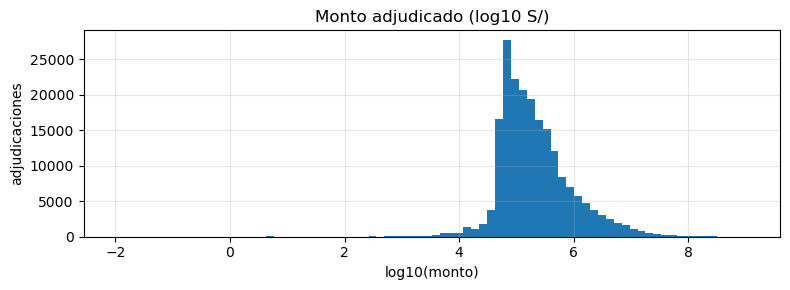

In [14]:
m = st["adjudicaciones"].where("monto_adj > 0").select(F.log10("monto_adj").alias("log10_monto")).toPandas()
plt.figure(figsize=(8, 3)); plt.hist(m.log10_monto, bins=80)
plt.title("Monto adjudicado (log10 S/)"); plt.xlabel("log10(monto)"); plt.ylabel("adjudicaciones")
mostrar_fig("monto_adj_log")

- **Monto referencial ≤ 0: 16,203 procesos (6.9%)**

- Cola pesada: mediana S/192k vs. p99 de S/23.1M; el máximo es S/1,135M (obras)

- La mitad central de los procesos cuesta entre S/88k y S/490k

- **Altos:** 8,240 procesos (3.5%) de más de S/6.4M; obras grandes reales (ANI, GR Loreto)

- **Bajos:** 1,400 procesos de menos de S/6,700; compras chicas

- 98.0% en soles; el resto (USD 1.8%, EUR, GBP…)

#### g. Fechas

In [15]:
fechas = (st["procesos"].agg(
    F.sum(F.col("fecha").isNull().cast("int")).alias("nulas"),
    F.sum((~F.year("fecha").isin(anios)).cast("int")).alias("fuera_2023_2025"),
    F.sum(((F.year("fecha") != F.col("anio_archivo")) | (F.month("fecha") != F.col("mes_archivo"))).cast("int")).alias("distinto_mes_archivo"),
    F.min("fecha").alias("min"), F.max("fecha").alias("max")).toPandas())
fechas

,nulas,fuera_2023_2025,distinto_mes_archivo,min,max
0,0,277,2918,2023-01-01,2026-09-25 10:18:16


- Sin fechas nulas pero con **275 procesos (0.1%) fuera de 2023-2025**

- 2,918 (1.2%) tienen fecha de un mes distinto al del archivo: se usa la fecha del proceso

### **6. Acciones previstas**

| Problema | Acción | Por qué |
|---|---|---|
| Entidad con código CONSUCODE | Clave `ENT:<consucode>`; el RUC queda como atributo | Identificador estable del SEACE |
| Ids con prefijos y RUC 10 | Extraer RUC → `RUC:`,con RUC 10 y DNI → clave `PN:` | Mismo actor no debe ser dos nodos |
| Consorcio con código propio | Clave `CONS:<código>` | Nombres son genéricos y se confunden |
| Extranjeros sin RUC | Clave `EXT:<código>` | Tienen código estable |
| Menciones sin identificador | Nombre exacto; clave existente y si no, nodo `NOM:` | Reutiliza la similitud |
| Mismo nombre con ids distintos | **No** se fusionan; se reportan como posibles vinculadas | Ids distintos = actores distintos |
| Adjudicación sin contrato | Arista por adjudicación; `tiene_contrato` como atributo | Usar contratos perdería el 10.8% |
| Sin estado del award | No se filtra | La fuente no lo publica |
| Monto ≤ 0, moneda ≠ PEN | Nulo / tipo de cambio BCRP | Comparabilidad |
| Montos extremos | Se conservan; se usa `log1p` | Son obras reales |
| Fecha fuera de 2023-2025 | Se excluye | Fuera del periodo |

---

### **7. Escritura de resultados**

Se guardan `paraquet` y `json` en `temp/a_entendimiento/`

In [16]:
escritos = guardar_tablas({"conteos_staging": conteos, "nulos_llaves": nulos, "formatos_id": formatos,
                           "duplicados_id": duplicados, "vinculo_adj_contrato": vinculo, "estados_adj": estados,
                           "consorcios": consorcios, "outliers_monto": outliers, "fechas": fechas})

Escrito en 00_EDA/temp/a_entendimiento/: conteos_staging, nulos_llaves, formatos_id, duplicados_id, vinculo_adj_contrato, estados_adj, consorcios, outliers_monto, fechas


#### a. Verificación

In [17]:
verificar_salidas(escritos)

OK: 9 tablas (parquet + json) | 2 figuras: monto_adj_log, nulos_llaves


---
### **8. Cerrar sesión**

In [18]:
spark.stop()